#### IMPORTS

In [2]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

current_dir = Path.cwd()
if current_dir.name in ["@data_analysis", "data_analysis"]:
    os.chdir("..")

project_root = str(Path.cwd().resolve())
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from data_analysis.utils.label_distribution import plot_label_distribution
from data_analysis.utils.language_detection import split_languages_in_csv
from data_analysis.utils.text_analysis import TextAnalyzer
from data_analysis.utils.text_preprocessing import TextPreprocessor


/Users/sachagodey/Desktop/ETH/Computational_Inteligence_LAB/project/text_classifier/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-04-16 14:44:56,952	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


## 1. Distribution of the Data

#### Distribution Plot Generation

In [6]:
plot_label_distribution("data/train.csv", "data_analysis/img/output.png")

'data_analysis/img/output.png'

### Plot Visualisation

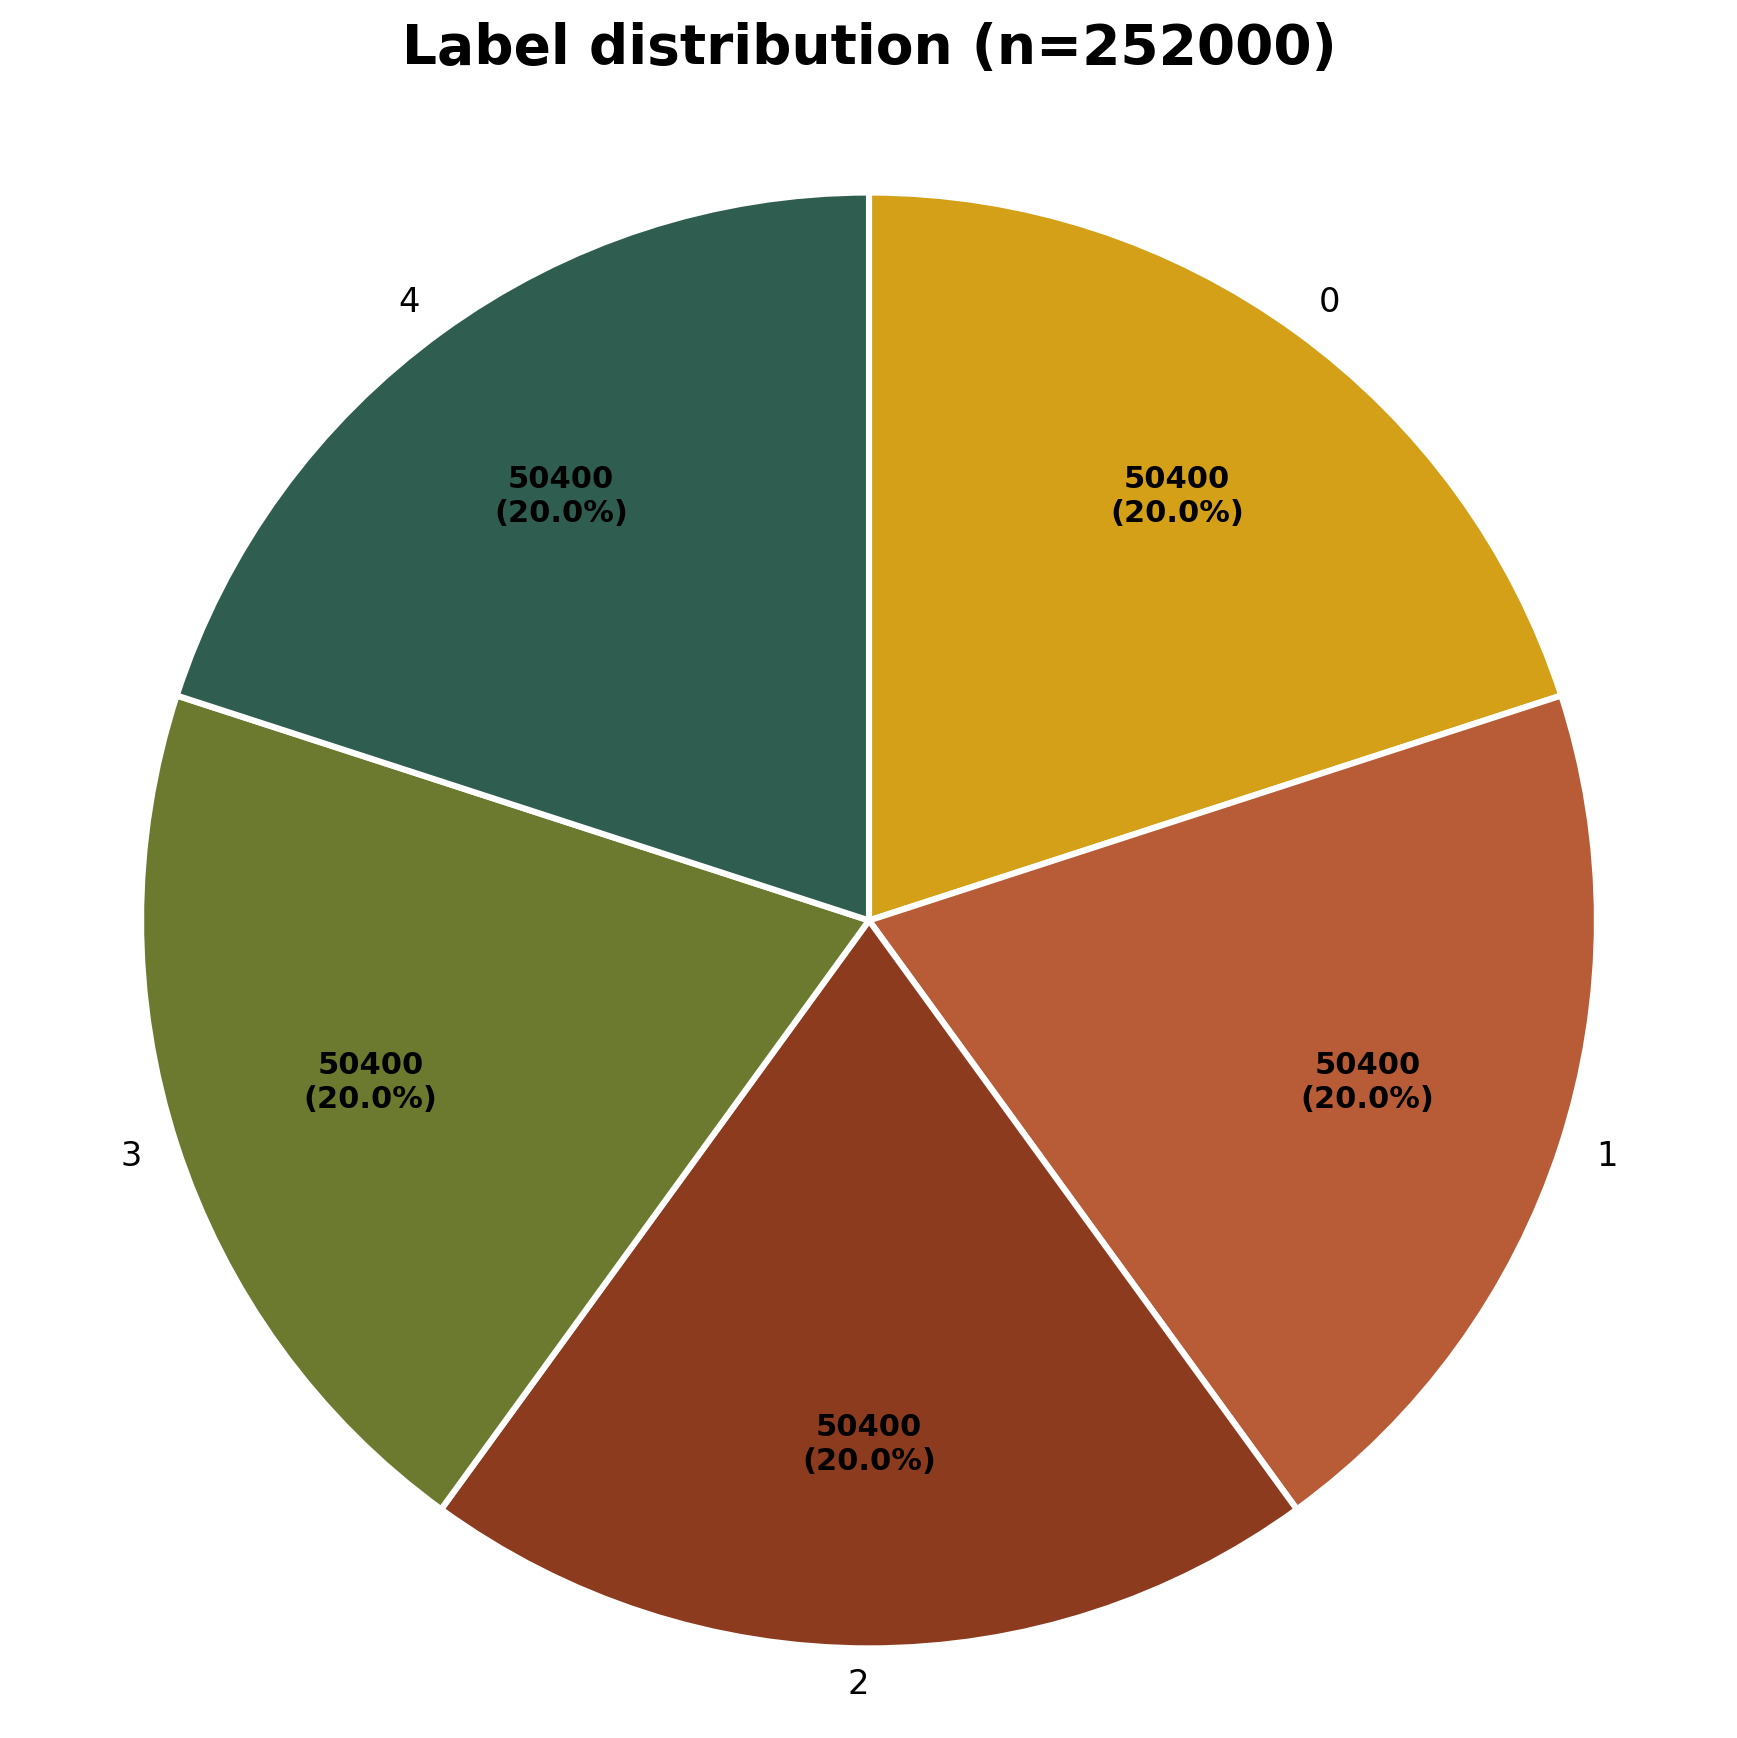

In [7]:
Image(filename="data_analysis/img/output.png", width = 600)

## Language Detection

### Generate the splits per langugage

In [8]:
split_languages_in_csv(
    input_filepath="data/train.csv",
    text_column="sentence",
    output_dir="data/splitlang",
    debug=True
)

2026-04-16 12:35:24,448	INFO worker.py:2012 -- Started a local Ray instance.


Detecting languages for 252000 rows in 126 batches (max 4 parallel workers)...
  8000/252000 rows processed...
  16000/252000 rows processed...
  24000/252000 rows processed...
  32000/252000 rows processed...
  40000/252000 rows processed...
  48000/252000 rows processed...
  56000/252000 rows processed...
  64000/252000 rows processed...
  72000/252000 rows processed...
  80000/252000 rows processed...
  88000/252000 rows processed...
  96000/252000 rows processed...
  104000/252000 rows processed...
  112000/252000 rows processed...
  120000/252000 rows processed...
  128000/252000 rows processed...
  136000/252000 rows processed...
  144000/252000 rows processed...
  152000/252000 rows processed...
  160000/252000 rows processed...
  168000/252000 rows processed...
  176000/252000 rows processed...
  184000/252000 rows processed...
  192000/252000 rows processed...
  200000/252000 rows processed...
  208000/252000 rows processed...
  216000/252000 rows processed...
  224000/252000 

{'EN': 'data/splitlang/EN/train.csv',
 'DE': 'data/splitlang/DE/train.csv',
 'AMBIGUOUS': 'data/splitlang/AMBIGUOUS/train.csv',
 'OTHER': 'data/splitlang/OTHER/train.csv',
 'DEBUG': 'data/splitlang/DEBUG/train.csv',
 'NER_CHANGES': 'data/splitlang/DEBUG/ner_changes_train.csv'}

In [ ]:
# ! ray stop --force

Stopped all 2 Ray processes.


In [3]:
en = pd.read_csv("data/splitlang/EN/train.csv")
de = pd.read_csv("data/splitlang/DE/train.csv")
ambiguous = pd.read_csv("data/splitlang/AMBIGUOUS/train.csv")
debug = pd.read_csv("data/splitlang/DEBUG/train.csv")




In [4]:
plot_label_distribution("data/splitlang/EN/train.csv", "data_analysis/img/EN_label_distribution.png")
plot_label_distribution("data/splitlang/DE/train.csv", "data_analysis/img/DE_label_distribution.png")

'data_analysis/img/DE_label_distribution.png'

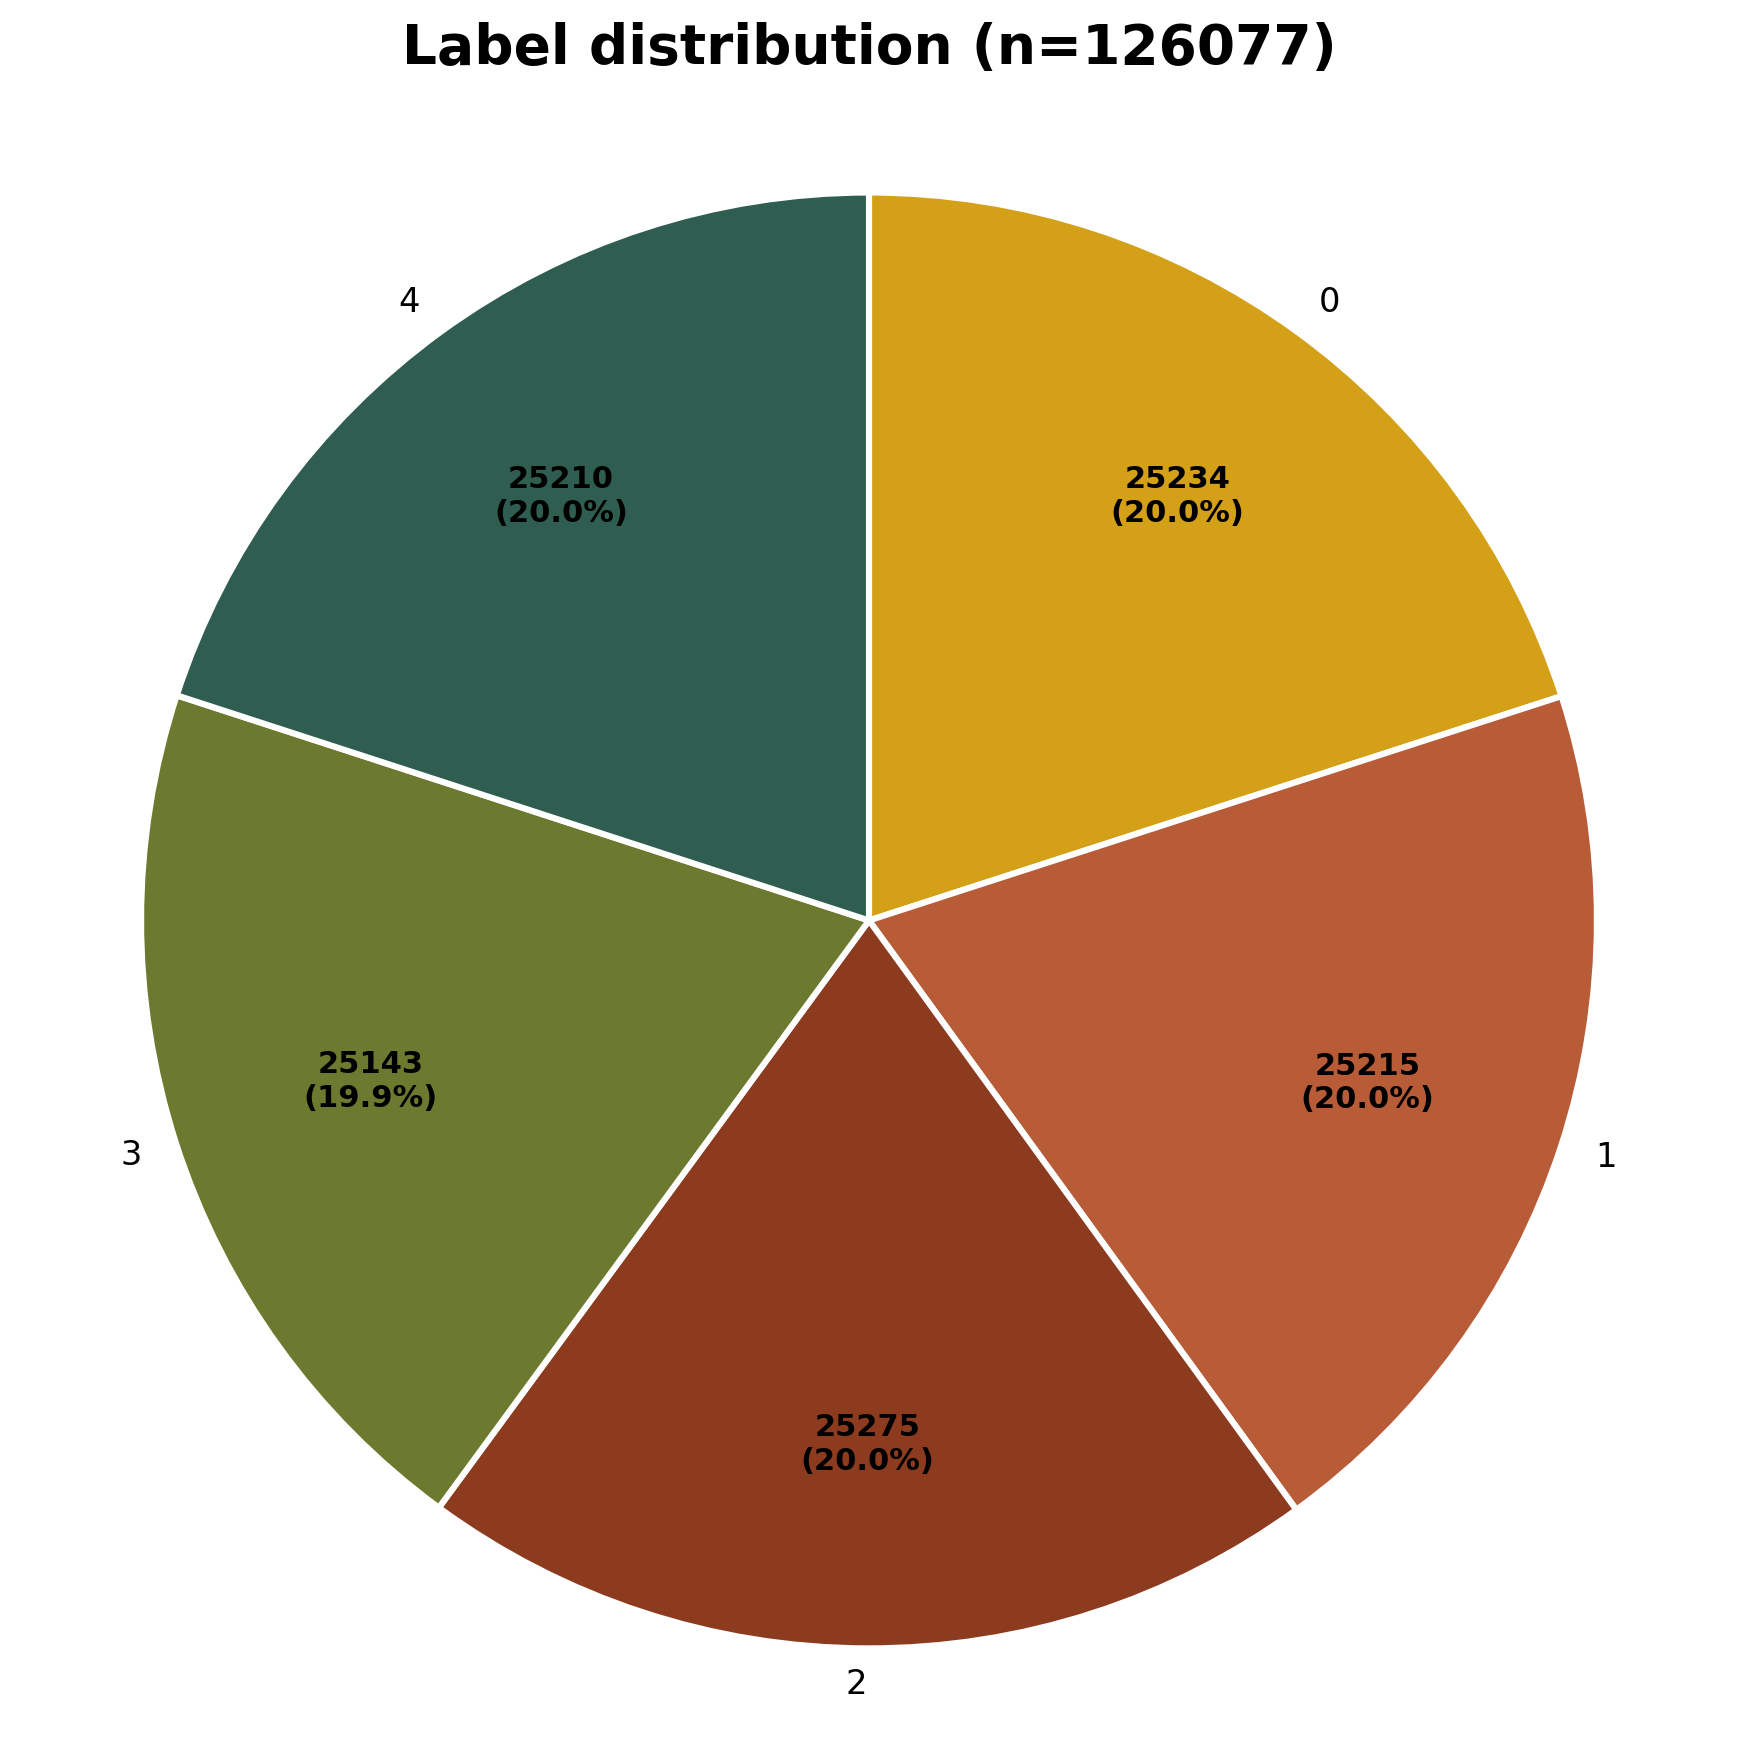

In [ ]:
Image(filename="data_analysis/img/EN_label_distribution.png", width = 600)

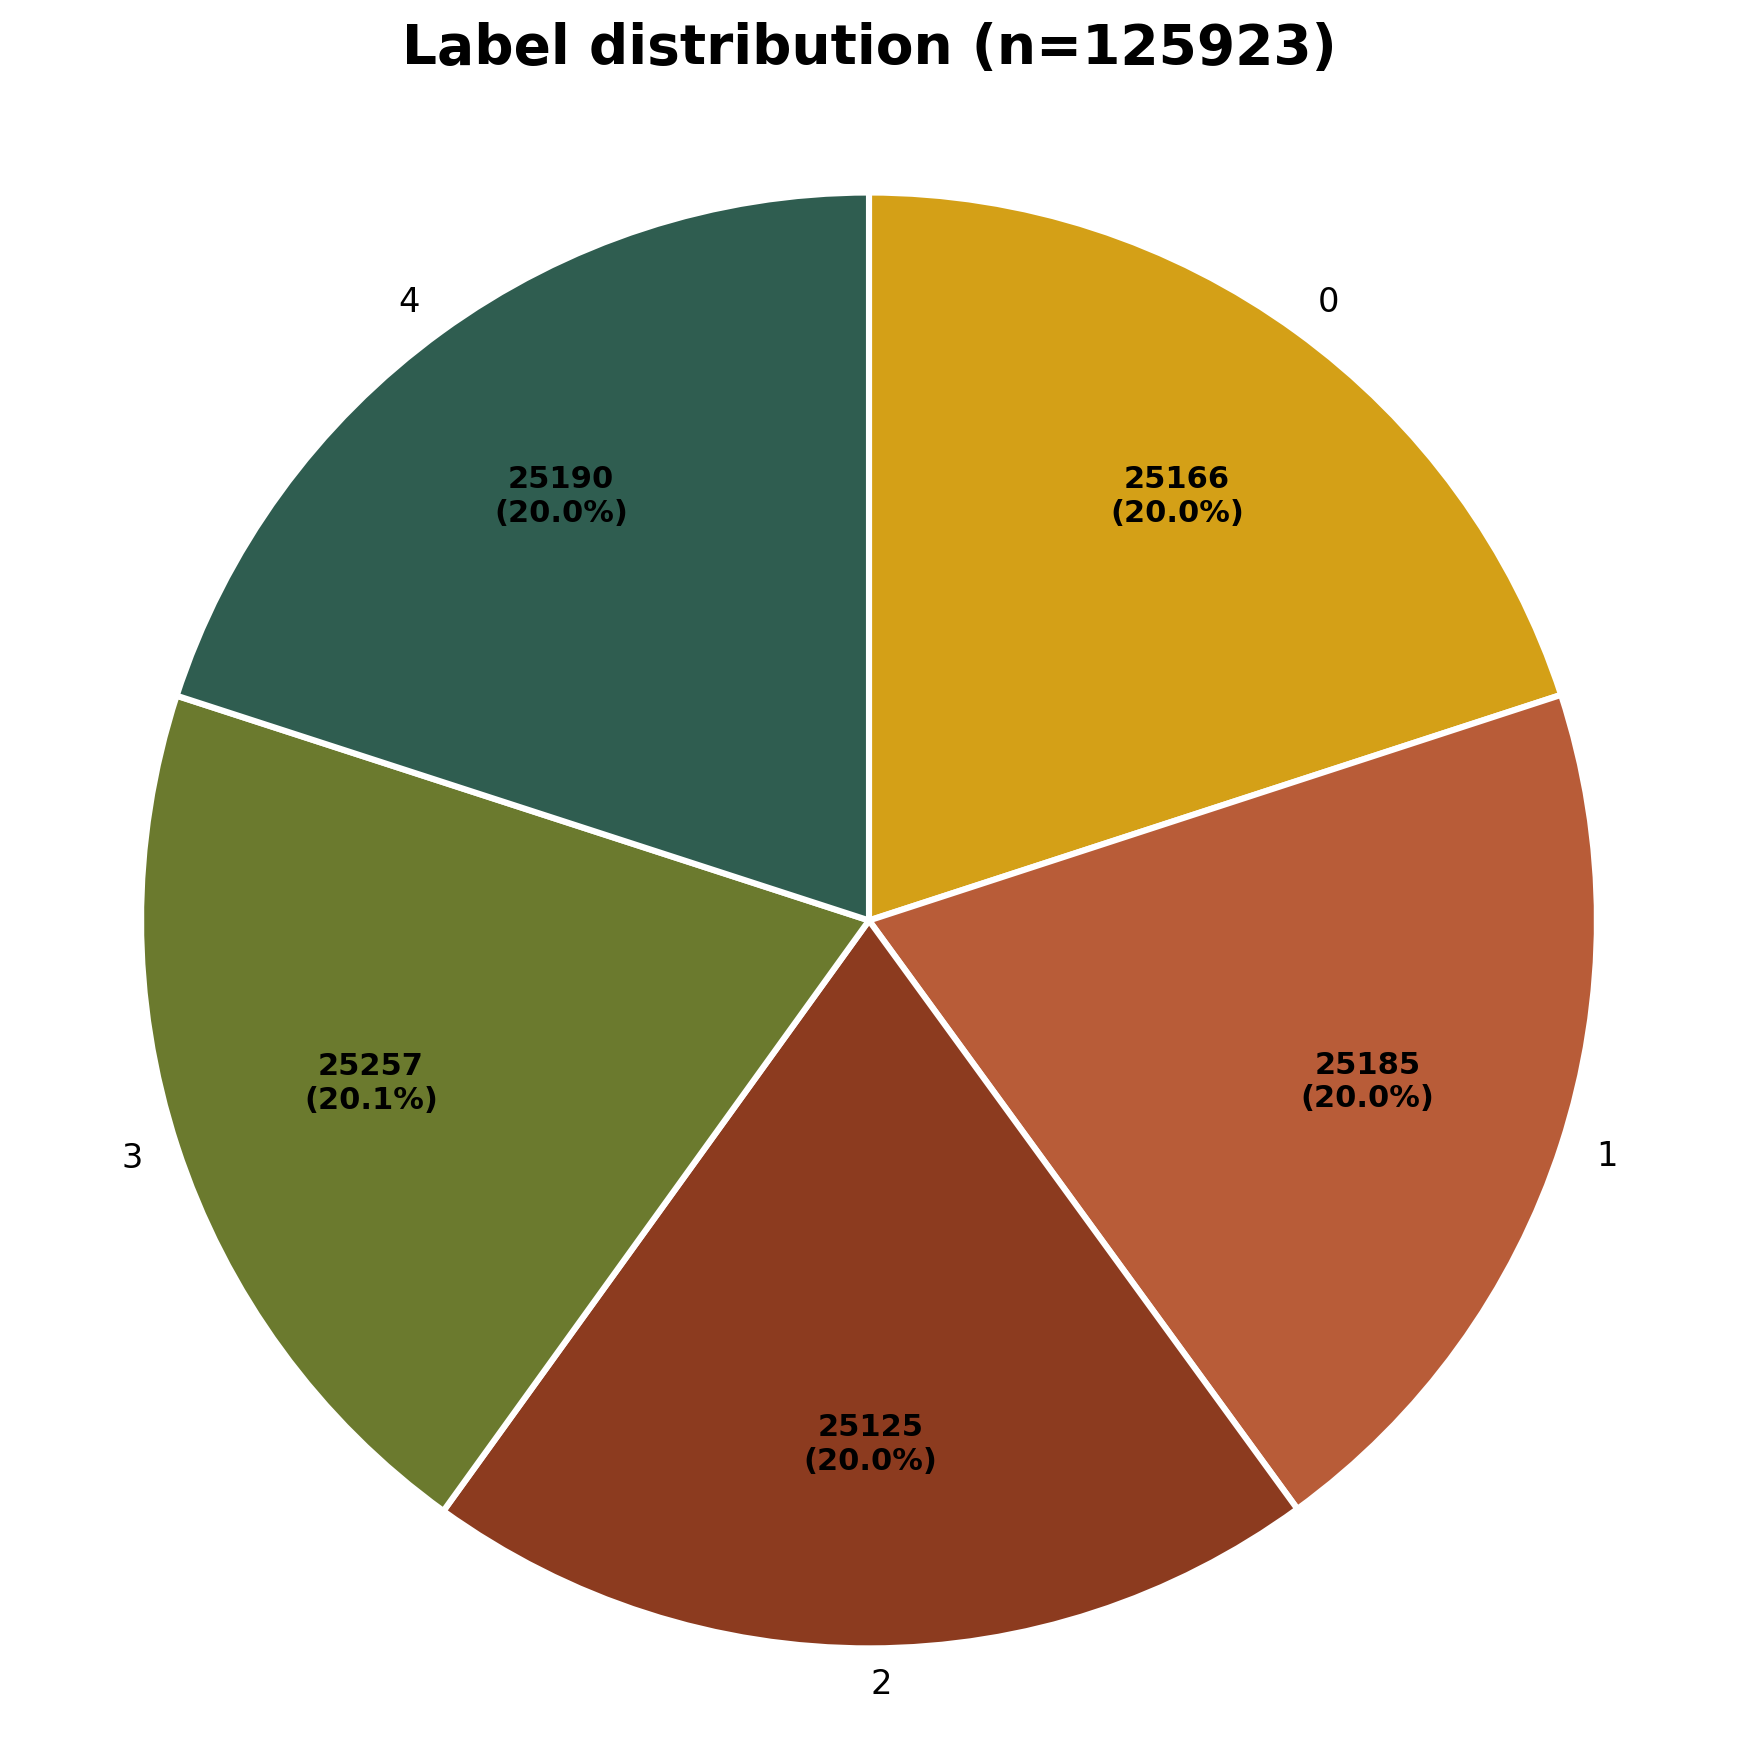

In [5]:
Image(filename="data_analysis/img/DE_label_distribution.png", width = 600)

## 3. Text Analysis Pipeline

In [7]:
# Load the full debug CSV (requires split_languages_in_csv to have been run with debug=True)
debug_path = "data/splitlang/DEBUG/train.csv"
ner_path   = "data/splitlang/DEBUG/ner_changes_train.csv"

debug = pd.read_csv(debug_path)
ner   = pd.read_csv(ner_path)

# Load spaCy (full pipeline — tagger + lemmatizer needed for analysis)
import spacy
nlp = spacy.load("en_core_web_sm")

analyzer = TextAnalyzer(nlp=nlp, sample_size=5000)

print(f'debug rows : {len(debug):,}')
print(f'NER-affected: {len(ner):,}')
print(debug.columns.tolist())


debug rows : 252,000
NER-affected: 38,559
['id', 'sentence', '_preprocessed_text', 'label', '_lang', '_lang_prob', '_en_prob', '_de_prob', '_all_preds', '_ambiguous_reason', '_ner_removed']


### 3.1 Dataset size per language / class

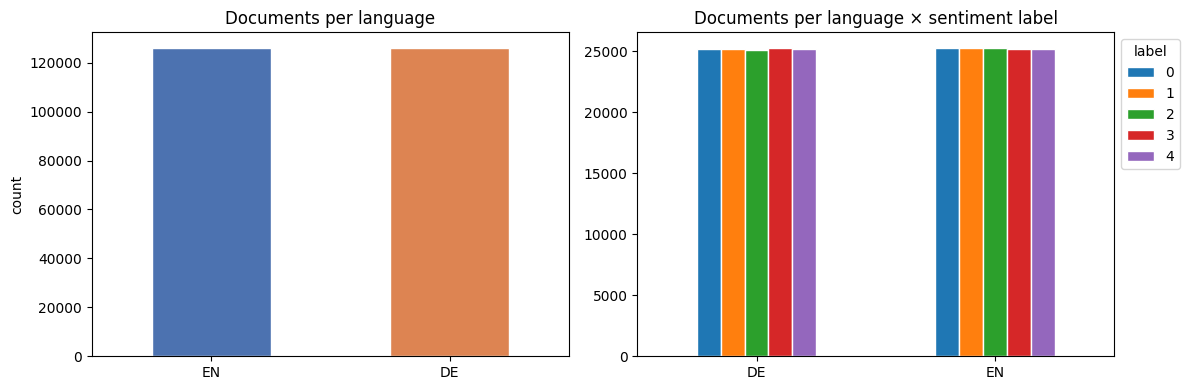

In [10]:
%matplotlib inline
lang_counts = debug['_lang'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: total per language
lang_counts.plot(kind='bar', ax=axes[0], color=['#4C72B0','#DD8452'], edgecolor='white')
axes[0].set_title('Documents per language')
axes[0].set_xlabel('')
axes[0].set_ylabel('count')
axes[0].tick_params(axis='x', rotation=0)

# Right: per language × label
lang_label = debug.groupby(['_lang','label']).size().unstack(fill_value=0)
lang_label.plot(kind='bar', ax=axes[1], edgecolor='white')
axes[1].set_title('Documents per language × sentiment label')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='label', bbox_to_anchor=(1,1))

plt.tight_layout()
plt.savefig('data_analysis/img/dataset_size.png', dpi=120, bbox_inches='tight')


### 3.2 Document length before vs after cleaning

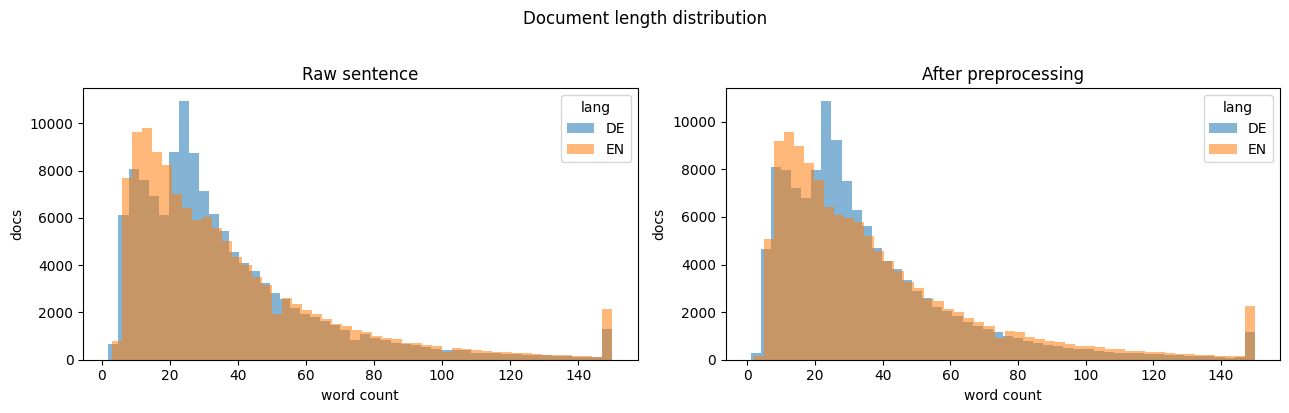

,raw_mean,raw_median,raw_max,clean_mean,clean_median,clean_max
_lang,,,,,,
DE,36.4,28.0,580,35.6,27.0,562
EN,38.6,29.0,737,39.3,29.0,763


In [11]:
# Word-count before (raw sentence) and after (preprocessed text)
debug['_raw_len']   = debug['sentence'].fillna('').str.split().str.len()
debug['_clean_len'] = debug['_preprocessed_text'].fillna('').str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, col, label, color in zip(
    axes,
    ['_raw_len', '_clean_len'],
    ['Raw sentence', 'After preprocessing'],
    ['#4C72B0', '#55A868'],
):
    for lang, grp in debug.groupby('_lang'):
        ax.hist(grp[col].clip(0, 150), bins=50, alpha=0.55, label=lang, edgecolor='none')
    ax.set_title(label)
    ax.set_xlabel('word count')
    ax.set_ylabel('docs')
    ax.legend(title='lang')

plt.suptitle('Document length distribution', y=1.02)
plt.tight_layout()
plt.savefig('data_analysis/img/doc_length.png', dpi=120, bbox_inches='tight')
plt.show()

# Summary table
summary = debug.groupby('_lang')[['_raw_len','_clean_len']].agg(['mean','median','max'])
summary.columns = ['raw_mean','raw_median','raw_max','clean_mean','clean_median','clean_max']
display(summary.round(1))


### 3.3 Top tokens per language

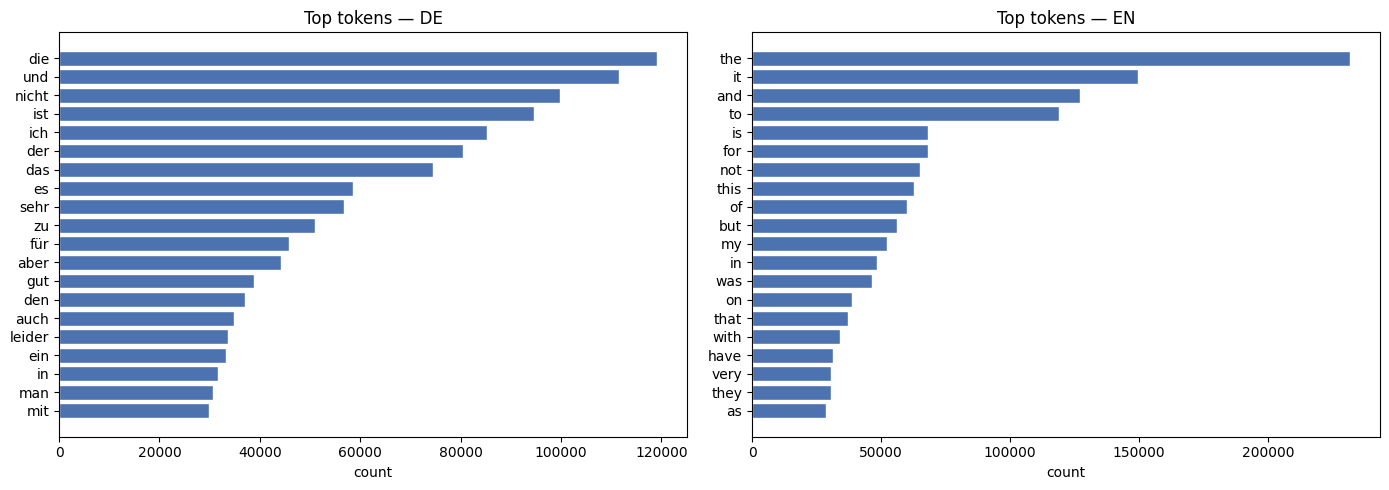

In [12]:
top_tok = analyzer.top_tokens(debug, text_col='sentence', group_col='_lang', n=20)

langs = top_tok['group'].unique()
fig, axes = plt.subplots(1, len(langs), figsize=(7 * len(langs), 5))
if len(langs) == 1:
    axes = [axes]

for ax, lang in zip(axes, langs):
    sub = top_tok[top_tok['group'] == lang].sort_values('count')
    ax.barh(sub['token'], sub['count'], color='#4C72B0', edgecolor='white')
    ax.set_title(f'Top tokens — {lang}')
    ax.set_xlabel('count')

plt.tight_layout()
plt.savefig('data_analysis/img/top_tokens.png', dpi=120, bbox_inches='tight')
plt.show()


### 3.4 Top lemmas per language

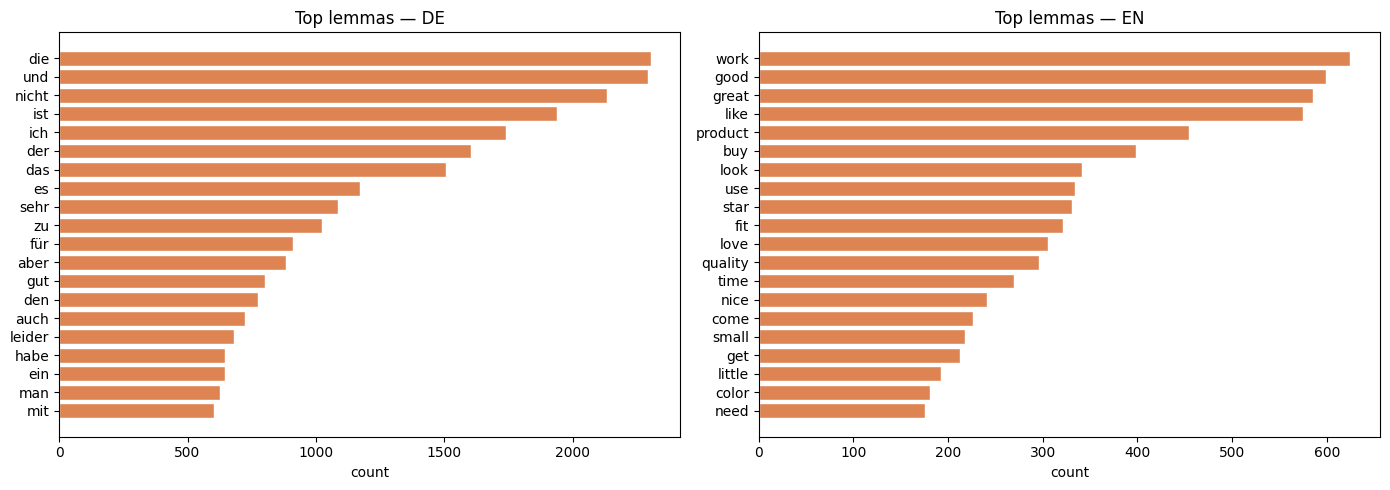

In [13]:
top_lem = analyzer.top_lemmas(debug, text_col='sentence', group_col='_lang', n=20)

langs = top_lem['group'].unique()
fig, axes = plt.subplots(1, len(langs), figsize=(7 * len(langs), 5))
if len(langs) == 1:
    axes = [axes]

for ax, lang in zip(axes, langs):
    sub = top_lem[top_lem['group'] == lang].sort_values('count')
    ax.barh(sub['lemma'], sub['count'], color='#DD8452', edgecolor='white')
    ax.set_title(f'Top lemmas — {lang}')
    ax.set_xlabel('count')

plt.tight_layout()
plt.savefig('data_analysis/img/top_lemmas.png', dpi=120, bbox_inches='tight')
plt.show()


### 3.5 Entity type counts

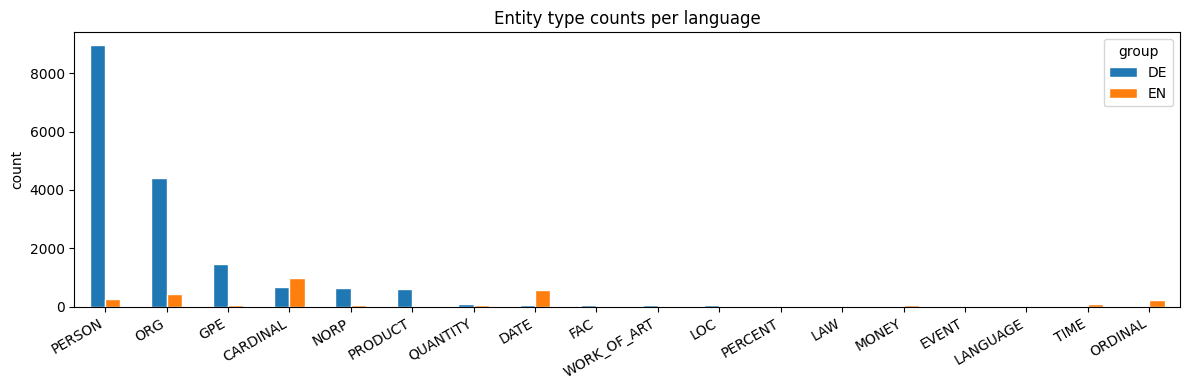

,group,span,count
0,DE,leider,286
1,DE,preis,237
2,DE,diese,164
3,DE,2,130
4,DE,nicht,123
5,DE,das,113
6,DE,qualität,111
7,DE,dem,110
8,DE,kann,93
9,DE,3,90


In [14]:
ent = analyzer.entity_stats(debug, text_col='sentence', group_col='_lang', n_top_spans=15)

# Entity type distribution
type_df = ent['type_counts'].pivot_table(index='entity_type', columns='group',
                                           values='count', fill_value=0)
type_df.sort_values(type_df.columns[0], ascending=False).plot(
    kind='bar', figsize=(12, 4), edgecolor='white'
)
plt.title('Entity type counts per language')
plt.xlabel('')
plt.ylabel('count')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('data_analysis/img/entity_types.png', dpi=120, bbox_inches='tight')
plt.show()

# Top spans
display(ent['top_spans'].head(20))


### 3.6 Top descriptor words removed inside product/org spans

In [15]:
desc = analyzer.descriptor_words_stats(
    ner, ner_removed_col='_ner_removed', group_col=None, n=25
)

if not desc.empty:
    desc_s = desc.sort_values('count')
    fig, ax = plt.subplots(figsize=(7, 8))
    ax.barh(desc_s['descriptor'], desc_s['count'], color='#C44E52', edgecolor='white')
    ax.set_title('Top descriptor words stripped from PRODUCT/ORG spans')
    ax.set_xlabel('count')
    plt.tight_layout()
    plt.savefig('data_analysis/img/descriptor_words.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('No descriptor words found — re-run split_languages_in_csv with debug=True.')


No descriptor words found — re-run split_languages_in_csv with debug=True.


### 3.7 Before / after cleaning examples

In [16]:
examples = analyzer.before_after_examples(
    debug,
    raw_col='sentence',
    preprocessed_col='_preprocessed_text',
    ner_removed_col='_ner_removed',
    n=15,
    only_changed=True,
)
pd.set_option('display.max_colwidth', 120)
display(examples)


,raw,preprocessed,ner_removed
0,Moderner Weihnachtsbaum in weiß\n\nDieses Jahr wollte ich keinen echten Baum und so hab ich mich für einen modernen ...,moderner weihnachtsbaum in weiß dieses jahr wollte ich keinen echten baum und so hab ich mich für einen modernen kle...,Drähte [PERSON]
1,"Passt wie angegossen\n\nTasche kam schnell und gut Verpackt an, die kleine DJI Ryze Tello passt perfekt rein sowie d...",passt wie angegossen tasche kam schnell und gut verpackt an die kleine dji ryze tello passt perfekt rein sowie der c...,Reserve Propeller [PERSON]
2,Schlechte Qualität\n\nIch habe sehr lange auf diesen Käfig gespart. Leider muss ich mich den vorherigen Rezensionen ...,schlechte qualität ich habe sehr lange auf diesen käfig gespart leider muss ich mich den vorherigen rezensionen ansc...,NaN
3,Bestellung nie angekommen\n\n-5 Sterne..... Am 15.5 bestellt und bis jetzt immer noch nicht da. Das Teil können Sie ...,bestellung nie angekommen 5 sterne am 15 5 bestellt und bis jetzt immer noch nicht da das teil können sie behalten,NaN
4,"Für mich gar nicht gut\n\nMacht das Makeup gar nicht haltbarer. Hinterlässt ein klebriges Gefühl auf der Haut, was g...",für mich gar nicht gut macht das makeup gar nicht haltbarer hinterlässt ein klebriges gefühl auf der haut was gar ni...,NaN
5,Jürgen Boos\n\nLäuft nicht auf allen meinen Geräten einwandfrei.,jürgen boos läuft nicht auf allen meinen geräten einwandfrei,NaN
6,"I hope they get it togather.\n\nThe design was good. The bad part it did not preform, I used an extra att. still not...",i hope they get it togather the design was good the bad part it did not preform i used an extra att still not good o...,NaN
7,"Schön aber naja..\n\nSitzt ein bisschen weit und der Stoff ist sehr dünn. Farbe und Druck sind toll, bin gespannt wi...",schön aber naja sitzt ein bisschen weit und der stoff ist sehr dünn farbe und druck sind toll bin gespannt wie es na...,NaN
8,Angenehm zu tragen.\n\nSehr praktisch. Leider keine Unterteilung fürs Handy. Das rutscht in der großen Tasche immer ...,angenehm zu tragen sehr praktisch leider keine unterteilung fürs handy das rutscht in der großen tasche immer nach u...,NaN
9,"Eh - for me, anyway\n\nFeel was ok-ish, didn’t care for the color. Hard to tell online, it’s lighter than I wanted. ...",eh for me anyway feel was ok ish didn t care for the color hard to tell online it s lighter than i wanted they did h...,NaN


### 3.8 Cleaning rule diagnostics

/Users/sachagodey/Desktop/ETH/Computational_Inteligence_LAB/project/text_classifier/data_analysis/utils/text_analysis.py:390: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ("collapse_punctuation", texts.str.contains(r"([!?.,;:\-])\1+", regex=True)),


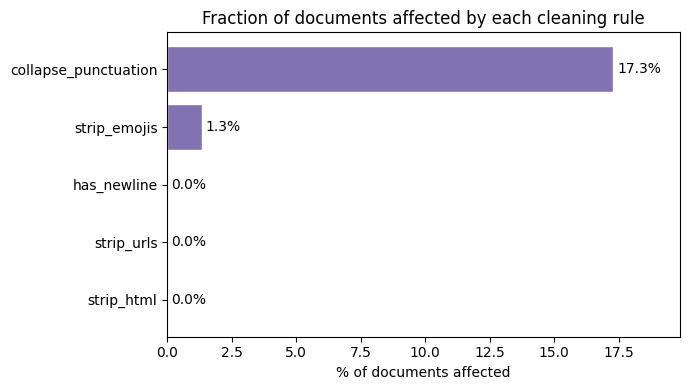

,rule,n_affected,pct_affected
0,strip_html,6,0.00
1,strip_urls,4,0.00
2,strip_emojis,3345,1.33
3,collapse_punctuation,43538,17.28
4,has_newline,1,0.00


In [17]:
diag = analyzer.rule_diagnostics(debug, text_col='sentence')

fig, ax = plt.subplots(figsize=(7, 4))
diag_s = diag.sort_values('pct_affected')
bars = ax.barh(diag_s['rule'], diag_s['pct_affected'], color='#8172B2', edgecolor='white')
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_xlabel('% of documents affected')
ax.set_title('Fraction of documents affected by each cleaning rule')
ax.set_xlim(0, diag_s['pct_affected'].max() * 1.15)
plt.tight_layout()
plt.savefig('data_analysis/img/rule_diagnostics.png', dpi=120, bbox_inches='tight')
plt.show()

display(diag)


### 3.9 POS tag distribution

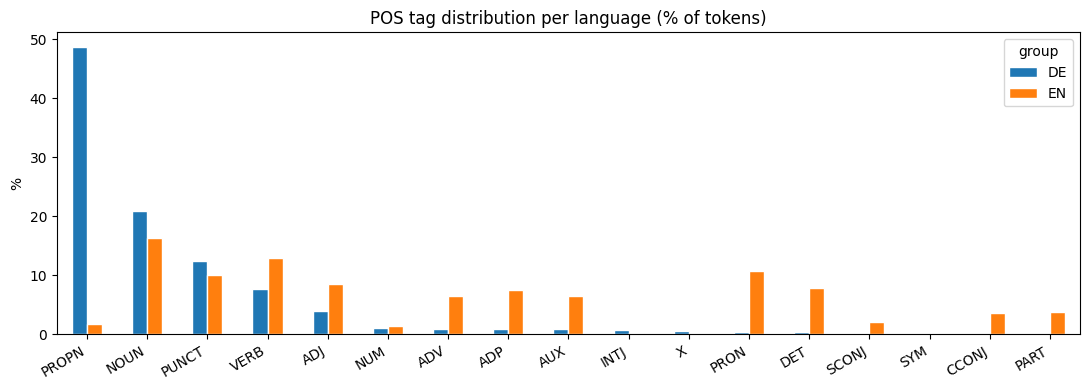

In [18]:
pos_df = analyzer.pos_distribution(debug, text_col='sentence', group_col='_lang')

pos_pivot = pos_df.pivot_table(index='pos', columns='group', values='count', fill_value=0)
pos_pivot = pos_pivot.div(pos_pivot.sum()).mul(100)  # normalise to %
pos_pivot.sort_values(pos_pivot.columns[0], ascending=False).plot(
    kind='bar', figsize=(11, 4), edgecolor='white'
)
plt.title('POS tag distribution per language (% of tokens)')
plt.xlabel('')
plt.ylabel('%')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('data_analysis/img/pos_distribution.png', dpi=120, bbox_inches='tight')
plt.show()


### 3.10 Ablation table

Each row disables one preprocessing step and measures the downstream
language-detection quality (ambiguous + forced-override count as errors).
Run the cell below once the classifier is in place to fill in the metric column.


In [19]:
# Build per-variant preprocessors and evaluate on a held-out sample
from data_analysis.utils.language_detection import split_languages_in_csv

configs = analyzer.ablation_configs()

# Placeholder — replace `metric` with your actual evaluation function
rows = []
for cfg in configs:
    name = cfg.pop('name')
    preprocessor = TextPreprocessor(**cfg)
    rows.append({'variant': name, 'strip_html': cfg.get('strip_html'), 
                 'remove_urls': cfg.get('remove_urls'),
                 'strip_emojis': cfg.get('strip_emojis'),
                 'collapse_punctuation': cfg.get('collapse_punctuation'),
                 'filter_entities': cfg.get('filter_entities'),
                 'use_spacy_ner': cfg.get('use_spacy_ner'),
                 'metric': '—'})  # TODO: fill in

ablation = pd.DataFrame(rows).set_index('variant')
display(ablation)


,strip_html,remove_urls,strip_emojis,collapse_punctuation,filter_entities,use_spacy_ner,metric
variant,,,,,,,
full_pipeline,True,True,True,True,True,True,—
no_strip_html,False,True,True,True,True,True,—
no_remove_urls,True,False,True,True,True,True,—
no_strip_emojis,True,True,False,True,True,True,—
no_collapse_punctuation,True,True,True,False,True,True,—
no_filter_entities,True,True,True,True,False,True,—
no_use_spacy_ner,True,True,True,True,True,False,—
fasttext_entity_filter,True,True,True,True,True,False,—
no_entity_filter,True,True,True,True,False,True,—
